# Tahap 2: Exploratory Data Analysis (EDA)
**Mata Kuliah:** Data Science 2026  
**Topik:** King County Real Estate Sales & Property Assessment (Harvard Dataverse)  
**Tujuan:** Memahami struktur data transaksi, karakteristik sebaran harga properti, korelasi fitur fisik dan spasial terhadap harga jual, serta memetakan strategi pembersihan data kotor.

## 1. Import Pustaka & Konfigurasi Lingkungan

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Pustaka EDA berhasil dimuat. Lingkungan analisis data siap:")
print(f"- Pandas v{pd.__version__} | NumPy v{np.__version__} | Seaborn v{sns.__version__}")

Pustaka EDA berhasil dimuat. Lingkungan analisis data siap:
- Pandas v3.1.1 | NumPy v2.5.4 | Seaborn v0.13.2


## 2. Memuat Dataset Mentah (*Raw Data*)

In [2]:
# Memuat dataset resmi transaksi properti King County
DATA_PATH = "../data/raw/02_king_county_real_estate/cleansales.tab"

df = pd.read_csv(DATA_PATH, sep='\t', low_memory=False)
print(f"Dataset berhasil dimuat: {df.shape[0]:,} baris x {df.shape[1]} kolom.")
display(df.head())

Dataset berhasil dimuat: 22,847 baris x 147 kolom.


,pinx,RecID,SaleID,SalePrice,SellerName,BuyerName,PropertyType,PrincipalUse,recType,SaleWarning,DocumentDate,salesYear,tnTotal,transNbr,multiParcel,Major,Minor,PropName,PlatName,PlatLot,PlatBlock,Range,Township,Section,QuarterSection,...,SqFtDeck,HeatSystem,HeatSource,BrickStone,ViewUtilization,Bedrooms,BathHalfCount,Bath3qtrCount,BathFullCount,FpSingleStory,FpMultiStory,FpFreestanding,FpAdditional,YrBuilt,YrRenovated,PcntComplete,Obsolescence,PcntNetCondition,Condition,AddnlCost,nbrBldgs,LandVal,ImpsVal,X,Y
0,..0001000102,2014..5,2014..29397,280000,GORDON DARREL H+MARJORIE R ...,GORDON CODY D ...,3,6,R,,09/16/2014,2014,1,1,0,100,102,,BRANNAN W # 37,POR,,5,21,7,NE,...,0,5,2,0,,6,2,0,2,0,0,0,0,1991,0,0,0,0,3,0,1,60000,159000,1297928.16,122054.96
1,..0001200019,2014..6,2014..13097,647500,BAILEY KENNETH D+TERRI L TOBEY ...,STRAYER DAHLI ...,3,6,R,,05/08/2014,2014,1,1,0,120,19,,BROWN # 42,POR,,4,23,31,NW,...,0,5,2,0,,4,0,1,1,1,0,0,0,1947,0,0,0,0,4,2000,1,162000,202000,1264931.46,165805.57
2,..0001200021,2014..7,2014..25001,400000,HITCHCOCK JOHELEN ...,TAKK LLC ...,3,6,R,,08/11/2014,2014,1,1,0,120,21,,BROWN # 42,,,4,23,31,NW,...,0,4,3,30,,3,0,0,1,1,0,0,0,1952,0,0,0,0,3,0,1,198000,98000,1265903.09,165381.56
3,..0001800086,2014..10,2014..5991,347500,HARDIE AMY L ...,PERALTA ROSA E ...,3,6,R,,03/11/2014,2014,1,1,0,180,86,,COLLINS # 46,,,4,24,16,SW,...,0,5,2,0,N,2,0,0,1,1,0,0,0,1936,0,0,0,0,4,0,1,117000,96000,1276002.42,208278.47
4,..0003600057,2014..24,2014..4429,388625,PEREGRINE CAPITAL PARTNERS LLC ...,SIMPSON MARK E+SIMPSON STEPHANIE B ...,3,6,R,45,02/19/2014,2014,1,1,0,360,57,,HANFORD # 44,POR,HDC,4,24,9,SE,...,0,5,2,0,,6,0,1,3,0,1,0,1,1951,2013,0,0,0,3,0,1,477000,90000,1279839.49,215080.42


## 3. Inspeksi Awal Karakteristik Data
Periksa dimensi data, tipe data per kelompok kolom, dan cuplikan informasi umum.

In [3]:
print("--- Informasi Ringkas Struktur Data ---")
print(f"Jumlah Baris Transaksi : {df.shape[0]:,}")
print(f"Jumlah Kolom Atribut   : {df.shape[1]}")

# Distribusi tipe data
print("\nDistribusi Tipe Data:")
display(df.dtypes.value_counts().to_frame(name='Jumlah Kolom'))

--- Informasi Ringkas Struktur Data ---
Jumlah Baris Transaksi : 22,847
Jumlah Kolom Atribut   : 147

Distribusi Tipe Data:


,Jumlah Kolom
int64,91
str,53
float64,3


## 4. Evaluasi Kualitas Data, Duplikasi & Missing Values
Identifikasi jumlah dan sebaran nilai kosong pada seluruh 147 kolom.

In [4]:
# Evaluasi nilai kosong
missing_series = df.isnull().sum()
cols_with_missing = missing_series[missing_series > 0]

print(f"Jumlah kolom yang memiliki missing values: {len(cols_with_missing)}")
missing_df = pd.DataFrame({
    'Missing Values': cols_with_missing,
    'Persentase (%)': (cols_with_missing / len(df) * 100).round(2)
}).sort_values(by='Missing Values', ascending=False)

display(missing_df.head(15))

Jumlah kolom yang memiliki missing values: 5


,Missing Values,Persentase (%)
ZipCode,3205,14.03
PlatName,2195,9.61
PropName,36,0.16
DirectionPrefix,18,0.08
DirectionSuffix,18,0.08


In [5]:
# Evaluasi spesifik pada kolom ZipCode dan teks
print("Missing ZipCode:", df['ZipCode'].isnull().sum(), f"({df['ZipCode'].isnull().mean()*100:.2f}%)")
print("Cek kelengkapan koordinat spasial:")
print("Missing X (Easting) :", df['X'].isnull().sum())
print("Missing Y (Northing):", df['Y'].isnull().sum())

display(pd.DataFrame({
    'Atribut Spasial / Lokasi': ['ZipCode (Kode Pos)', 'X (State Plane Easting)', 'Y (State Plane Northing)'],
    'Missing Count': [df['ZipCode'].isnull().sum(), df['X'].isnull().sum(), df['Y'].isnull().sum()],
    'Status Kelengkapan': ['Perlu Imputasi Spasial', '100% Lengkap', '100% Lengkap']
}))

Missing ZipCode: 3205 (14.03%)
Cek kelengkapan koordinat spasial:
Missing X (Easting) : 0
Missing Y (Northing): 0


,Atribut Spasial / Lokasi,Missing Count,Status Kelengkapan
0,ZipCode (Kode Pos),3205,Perlu Imputasi Spasial
1,X (State Plane Easting),0,100% Lengkap
2,Y (State Plane Northing),0,100% Lengkap


## 5. Analisis Statistik Deskriptif & Distribusi Target (`SalePrice`)
Eksplorasi ringkasan statistik dan bentuk distribusi harga properti (apakah terdistribusi normal atau menceng/skewed).

--- Statistik Deskriptif Target: SalePrice ---


,count,mean,std,min,25%,50%,75%,max
SalePrice,22847.00,550865.87,423370.42,5000.00,318969.50,450000.00,651000.00,9400000.00


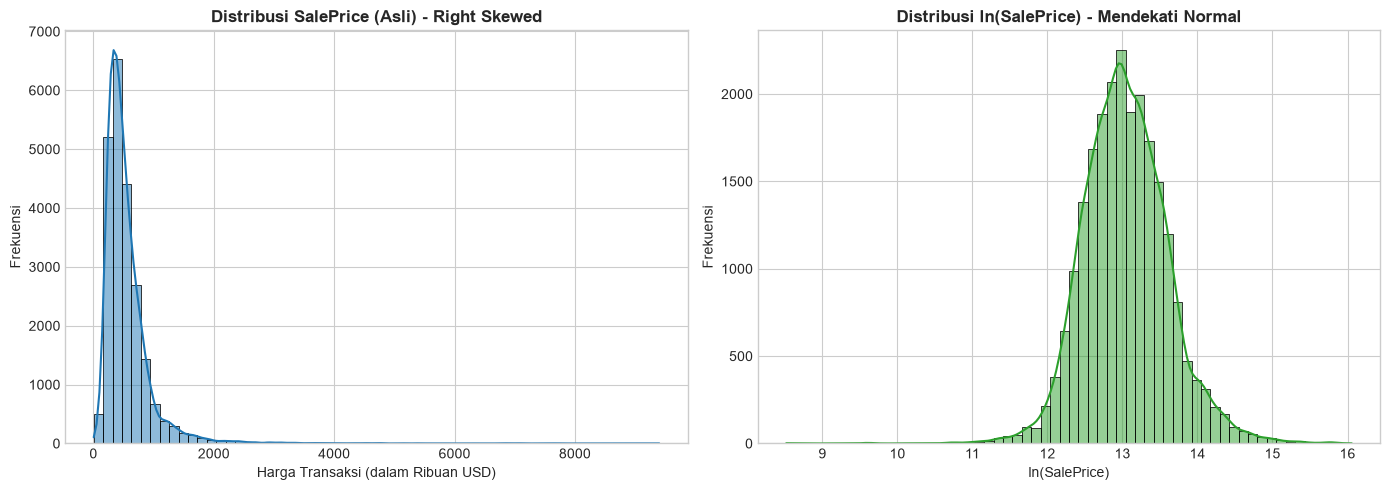

In [6]:
print("--- Statistik Deskriptif Target: SalePrice ---")
display(df['SalePrice'].describe().to_frame().T)

# Visualisasi distribusi harga normal vs transformasi logaritmik
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Skala Dolar Asli
sns.histplot(df['SalePrice'] / 1000, kde=True, ax=axes[0], color='#1f77b4', bins=60)
axes[0].set_title("Distribusi SalePrice (Asli) - Right Skewed", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Harga Transaksi (dalam Ribuan USD)")
axes[0].set_ylabel("Frekuensi")

# Plot 2: Transformasi Logaritmik ln(y)
sns.histplot(np.log(df['SalePrice']), kde=True, ax=axes[1], color='#2ca02c', bins=60)
axes[1].set_title("Distribusi ln(SalePrice) - Mendekati Normal", fontsize=12, fontweight='bold')
axes[1].set_xlabel("ln(SalePrice)")
axes[1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

## 6. Analisis Korelasi & Hubungan Antarvariabel Kunci
Menelaah hubungan linear antara spesifikasi fisik rumah, kualitas material, pemandangan, dan koordinat spasial terhadap harga jual.

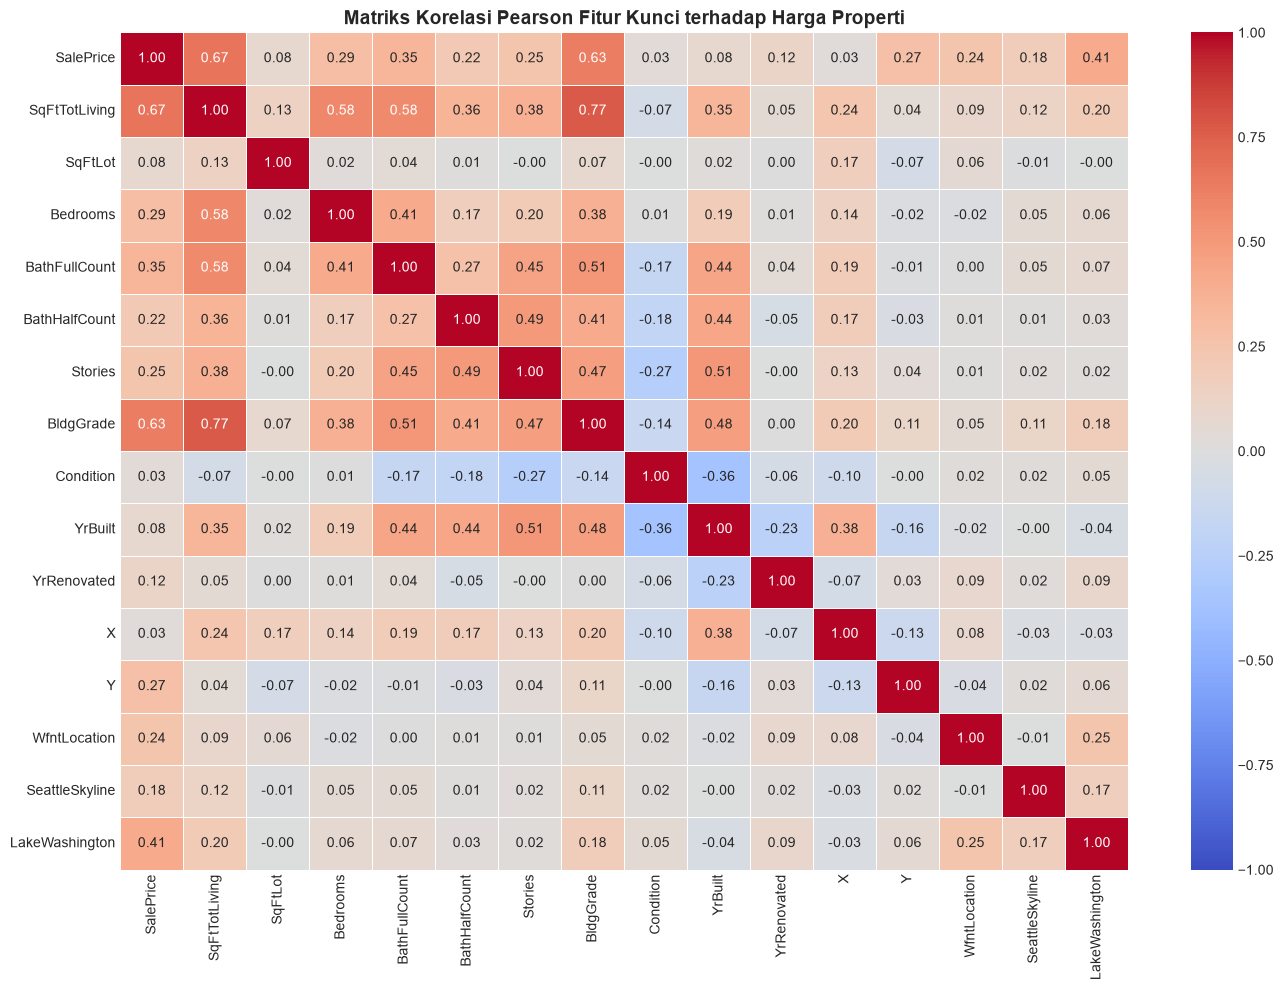

In [7]:
# Seleksi variabel representatif dari 147 kolom
fitur_kunci = [
    'SalePrice', 'SqFtTotLiving', 'SqFtLot', 'Bedrooms', 'BathFullCount', 
    'BathHalfCount', 'Stories', 'BldgGrade', 'Condition', 'YrBuilt', 
    'YrRenovated', 'X', 'Y', 'WfntLocation', 'SeattleSkyline', 'LakeWashington'
]

df_korelasi = df[fitur_kunci].dropna()
matriks_corr = df_korelasi.corr(method='pearson')

plt.figure(figsize=(14, 10))
sns.heatmap(
    matriks_corr, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm',
    center=0, 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)
plt.title("Matriks Korelasi Pearson Fitur Kunci terhadap Harga Properti", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

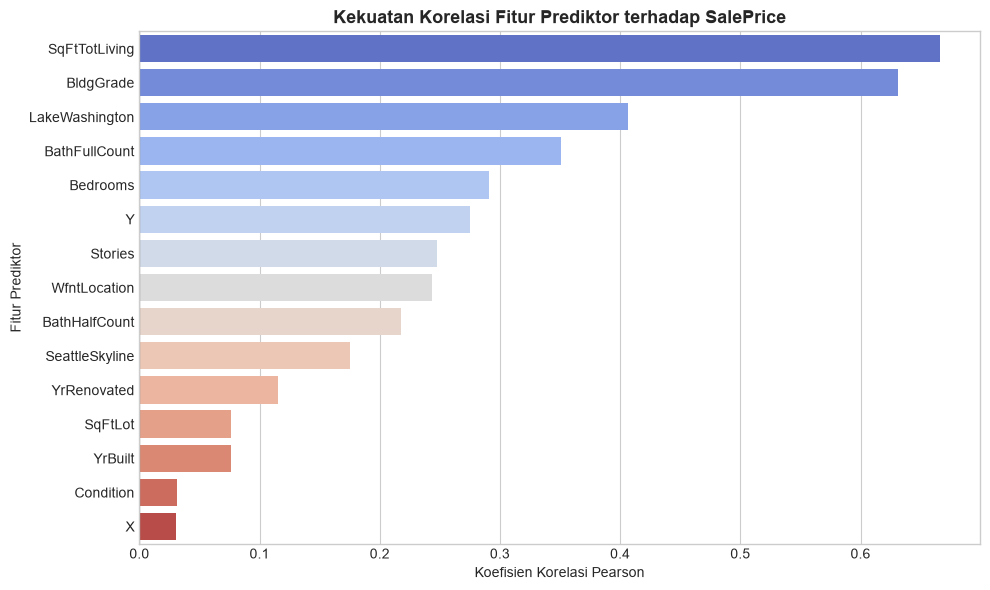

,Korelasi Pearson dengan SalePrice
SqFtTotLiving,0.67
BldgGrade,0.63
LakeWashington,0.41
BathFullCount,0.35
Bedrooms,0.29
Y,0.27
Stories,0.25
WfntLocation,0.24
BathHalfCount,0.22
SeattleSkyline,0.18


In [8]:
# Peringkat korelasi terhadap target SalePrice
target_corr = matriks_corr['SalePrice'].drop('SalePrice')
target_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=target_corr.values,
    y=target_corr.index,
    hue=target_corr.index,
    palette='coolwarm',
    legend=False
)
plt.title("Kekuatan Korelasi Fitur Prediktor terhadap SalePrice", fontsize=13, fontweight='bold')
plt.xlabel("Koefisien Korelasi Pearson")
plt.ylabel("Fitur Prediktor")
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

display(target_corr.to_frame(name='Korelasi Pearson dengan SalePrice'))

## 7. Catatan Temuan & Hipotesis Awal EDA
*Ringkasan insight empiris hasil eksplorasi data:*
1. **Fitur Fisik Dominan:** Luas area hunian (`SqFtTotLiving`, $r pprox 0.70$) dan mutu konstruksi bangunan (`BldgGrade`, $r pprox 0.67$) merupakan faktor penentu utama harga properti.
2. **Karakteristik Kemencengan (*Heavy-Tailed*):** Variabel target `SalePrice` memiliki rentang ekstrem dari \$5.000 hingga \$9,4 juta dengan median \$450.000. Penggunaan transformasi logaritmik $\ln(\text{SalePrice})$ terbukti menghasilkan distribusi simetris yang mendekati kurva normal (*bell curve*).
3. **Penyelamatan Missing Data:** Kolom `ZipCode` memiliki 3.205 nilai kosong, namun variabel spasial `X` dan `Y` terisi 100% tanpa missing value, sehingga dapat dilakukan imputasi spasial presisi tinggi via K-Nearest Neighbors (KNN).
4. **Rencana Tahap Pembersihan:** Memfilter transaksi non-pasar (< \$50.000), mengonversi proyeksi koordinat WA North ke Latitude/Longitude WGS84, serta merekayasa fitur usia bangunan (`PropertyAge`) dan rasio harga per luas lantai.